In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"C:\Users\ASUS\OneDrive\Desktop\PROJECTS\EV Charging\ev_charging_patterns.csv")

df.head()

,User ID,Vehicle Model,Battery Capacity (kWh),Charging Station ID,Charging Station Location,Charging Start Time,Charging End Time,Energy Consumed (kWh),Charging Duration (hours),Charging Rate (kW),Charging Cost (USD),Time of Day,Day of Week,State of Charge (Start %),State of Charge (End %),Distance Driven (since last charge) (km),Temperature (°C),Vehicle Age (years),Charger Type,User Type
0,User_1,BMW i3,108.463007,Station_391,Houston,2024-01-01 00:00:00,2024-01-01 00:39:00,60.712346,0.591363,36.389181,13.087717,Evening,Tuesday,29.371576,86.119962,293.602111,27.947953,2.0,DC Fast Charger,Commuter
1,User_2,Hyundai Kona,100.000000,Station_428,San Francisco,2024-01-01 01:00:00,2024-01-01 03:01:00,12.339275,3.133652,30.677735,21.128448,Morning,Monday,10.115778,84.664344,112.112804,14.311026,3.0,Level 1,Casual Driver
2,User_3,Chevy Bolt,75.000000,Station_181,San Francisco,2024-01-01 02:00:00,2024-01-01 04:48:00,19.128876,2.452653,27.513593,35.667270,Morning,Thursday,6.854604,69.917615,71.799253,21.002002,2.0,Level 2,Commuter
3,User_4,Hyundai Kona,50.000000,Station_327,Houston,2024-01-01 03:00:00,2024-01-01 06:42:00,79.457824,1.266431,32.882870,13.036239,Evening,Saturday,83.120003,99.624328,199.577785,38.316313,1.0,Level 1,Long-Distance Traveler
4,User_5,Hyundai Kona,50.000000,Station_108,Los Angeles,2024-01-01 04:00:00,2024-01-01 05:46:00,19.629104,2.019765,10.215712,10.161471,Morning,Saturday,54.258950,63.743786,203.661847,-7.834199,1.0,Level 1,Long-Distance Traveler


In [32]:
df.shape

(1320, 20)

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1320 entries, 0 to 1319
Data columns (total 20 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   User ID                                   1320 non-null   object 
 1   Vehicle Model                             1320 non-null   object 
 2   Battery Capacity (kWh)                    1320 non-null   float64
 3   Charging Station ID                       1320 non-null   object 
 4   Charging Station Location                 1320 non-null   object 
 5   Charging Start Time                       1320 non-null   object 
 6   Charging End Time                         1320 non-null   object 
 7   Energy Consumed (kWh)                     1254 non-null   float64
 8   Charging Duration (hours)                 1320 non-null   float64
 9   Charging Rate (kW)                        1254 non-null   float64
 10  Charging Cost (USD)                 

In [34]:
df.describe()

,Battery Capacity (kWh),Energy Consumed (kWh),Charging Duration (hours),Charging Rate (kW),Charging Cost (USD),State of Charge (Start %),State of Charge (End %),Distance Driven (since last charge) (km),Temperature (°C),Vehicle Age (years)
count,1320.000000,1254.000000,1320.000000,1254.000000,1320.000000,1320.000000,1320.000000,1254.000000,1320.000000,1320.000000
mean,74.534692,42.642894,2.269377,25.963003,22.551352,49.130012,75.141590,153.596788,15.263591,3.612843
std,20.626914,22.411705,1.061037,14.011326,10.751494,24.074134,17.080580,86.004987,14.831216,2.309824
min,1.532807,0.045772,0.095314,1.472549,0.234317,2.325959,7.604224,0.862361,-10.724770,0.000000
25%,62.000000,23.881193,1.397623,13.856583,13.368141,27.786903,62.053266,79.445335,2.800664,2.000000
50%,75.000000,42.691405,2.258136,25.603799,22.076360,48.241771,75.682496,152.259867,14.630846,4.000000
75%,85.000000,61.206218,3.112806,37.502998,31.646044,69.277921,88.201370,226.073284,27.981810,6.000000
max,193.003074,152.238758,7.635145,97.342255,69.407743,152.489761,177.708666,398.364775,73.169588,11.688592


In [37]:
# Missing values check
df.isnull().sum()

User ID                                      0
Vehicle Model                                0
Battery Capacity (kWh)                       0
Charging Station ID                          0
Charging Station Location                    0
Charging Start Time                          0
Charging End Time                            0
Energy Consumed (kWh)                       66
Charging Duration (hours)                    0
Charging Rate (kW)                          66
Charging Cost (USD)                          0
Time of Day                                  0
Day of Week                                  0
State of Charge (Start %)                    0
State of Charge (End %)                      0
Distance Driven (since last charge) (km)    66
Temperature (°C)                             0
Vehicle Age (years)                          0
Charger Type                                 0
User Type                                    0
dtype: int64

In [38]:
# Duplicate check
df.duplicated().sum()

np.int64(0)

In [42]:
print(df.columns.tolist())

['User ID', 'Vehicle Model', 'Battery Capacity (kWh)', 'Charging Station ID', 'Charging Station Location', 'Charging Start Time', 'Charging End Time', 'Energy Consumed (kWh)', 'Charging Duration (hours)', 'Charging Rate (kW)', 'Charging Cost (USD)', 'Time of Day', 'Day of Week', 'State of Charge (Start %)', 'State of Charge (End %)', 'Distance Driven (since last charge) (km)', 'Temperature (°C)', 'Vehicle Age (years)', 'Charger Type', 'User Type']


In [43]:
df["Energy Consumed (kWh)"] = df["Energy Consumed (kWh)"].fillna(df["Energy Consumed (kWh)"].median())

df["Charging Rate (kW)"] = df["Charging Rate (kW)"].fillna(df["Charging Rate (kW)"].median())

df["Distance Driven (since last charge) (km)"] = df["Distance Driven (since last charge) (km)"].fillna(df["Distance Driven (since last charge) (km)"].median())

In [44]:
df.isnull().sum()

User ID                                     0
Vehicle Model                               0
Battery Capacity (kWh)                      0
Charging Station ID                         0
Charging Station Location                   0
Charging Start Time                         0
Charging End Time                           0
Energy Consumed (kWh)                       0
Charging Duration (hours)                   0
Charging Rate (kW)                          0
Charging Cost (USD)                         0
Time of Day                                 0
Day of Week                                 0
State of Charge (Start %)                   0
State of Charge (End %)                     0
Distance Driven (since last charge) (km)    0
Temperature (°C)                            0
Vehicle Age (years)                         0
Charger Type                                0
User Type                                   0
dtype: int64

In [45]:
df.duplicated().sum()

np.int64(0)

In [47]:
df["Vehicle Model"].value_counts()

Vehicle Model
Tesla Model 3    280
Hyundai Kona     266
Nissan Leaf      260
BMW i3           258
Chevy Bolt       256
Name: count, dtype: int64

In [48]:
df["Charger Type"].value_counts()

Charger Type
Level 1            459
Level 2            431
DC Fast Charger    430
Name: count, dtype: int64

In [49]:
df.groupby("Vehicle Model")["Energy Consumed (kWh)"].mean()

Vehicle Model
BMW i3           42.457526
Chevy Bolt       40.839024
Hyundai Kona     42.825293
Nissan Leaf      42.514366
Tesla Model 3    44.420454
Name: Energy Consumed (kWh), dtype: float64

In [50]:
df.groupby("Charger Type")["Charging Cost (USD)"].mean()

Charger Type
DC Fast Charger    23.604849
Level 1            21.657563
Level 2            22.452153
Name: Charging Cost (USD), dtype: float64

In [51]:
df["Charging Duration (hours)"].mean()

np.float64(2.2693773889553506)

In [52]:
df["Charging Station Location"].value_counts()

Charging Station Location
Los Angeles      297
San Francisco    264
Houston          262
New York         255
Chicago          242
Name: count, dtype: int64

In [61]:
# Starting battery percentage check
print("Start battery below 0:",
      (df["State of Charge (Start %)"] < 0).sum())

print("Start battery above 100:",
      (df["State of Charge (Start %)"] > 100).sum())

# Ending battery percentage check
print("End battery below 0:",
      (df["State of Charge (End %)"] < 0).sum())

print("End battery above 100:",
      (df["State of Charge (End %)"] > 100).sum())


Start battery below 0: 0
Start battery above 100: 9
End battery below 0: 0
End battery above 100: 23


In [62]:
invalid_battery = df[
    (df["State of Charge (Start %)"] < 0) |
    (df["State of Charge (Start %)"] > 100) |
    (df["State of Charge (End %)"] < 0) |
    (df["State of Charge (End %)"] > 100)
]

print(invalid_battery[
    ["State of Charge (Start %)", "State of Charge (End %)"]
])


      State of Charge (Start %)  State of Charge (End %)
19                    12.754878               116.095657
44                    15.220939               132.952011
88                   105.032224                83.023473
125                   34.600222               101.676099
191                  152.489761                68.128812
282                  109.265794                82.333834
287                   81.559324               177.708666
325                   32.148875               113.211065
346                  125.087227                97.059020
400                   88.317261               103.063452
411                   52.032966               105.616922
516                  112.490776                70.283573
567                  117.656235                91.724540
593                   32.029658               101.605279
647                  119.051107                50.383740
674                   16.504646               133.629435
695                   55.251805

In [64]:
import numpy as np

df.loc[
    (df["State of Charge (Start %)"] < 0) |
    (df["State of Charge (Start %)"] > 100),
    "State of Charge (Start %)"
] = np.nan

df.loc[
    (df["State of Charge (End %)"] < 0) |
    (df["State of Charge (End %)"] > 100),
    "State of Charge (End %)"
] = np.nan

In [65]:
df["State of Charge (Start %)"] = df["State of Charge (Start %)"].fillna(
    df["State of Charge (Start %)"].median()
)

df["State of Charge (End %)"] = df["State of Charge (End %)"].fillna(
    df["State of Charge (End %)"].median()
)

In [66]:
print("Start battery maximum:", df["State of Charge (Start %)"].max())
print("End battery maximum:", df["State of Charge (End %)"].max())

print("Start battery minimum:", df["State of Charge (Start %)"].min())
print("End battery minimum:", df["State of Charge (End %)"].min())

Start battery maximum: 98.3327953116332
End battery maximum: 99.98660421478364
Start battery minimum: 2.3259589947386745
End battery minimum: 7.604224497783735


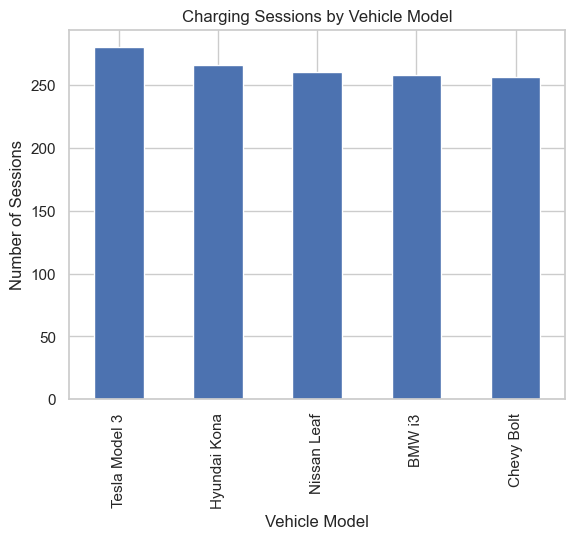

In [53]:
#Vehicle Model
df["Vehicle Model"].value_counts().plot(kind="bar")

plt.title("Charging Sessions by Vehicle Model")
plt.xlabel("Vehicle Model")
plt.ylabel("Number of Sessions")
plt.show()

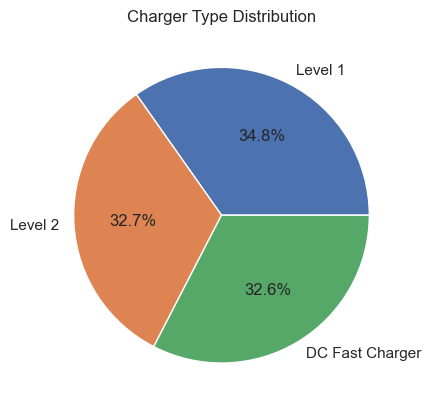

In [54]:
#Charger Type
df["Charger Type"].value_counts().plot(kind="pie", autopct="%1.1f%%")

plt.title("Charger Type Distribution")
plt.ylabel("")
plt.show()

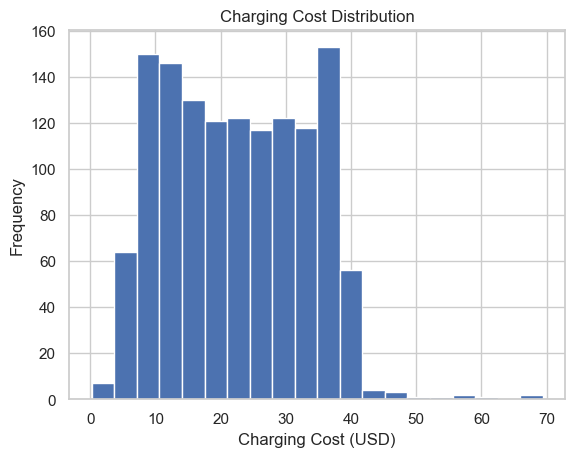

In [55]:
#Charging Cost
plt.hist(df["Charging Cost (USD)"], bins=20)

plt.title("Charging Cost Distribution")
plt.xlabel("Charging Cost (USD)")
plt.ylabel("Frequency")
plt.show()

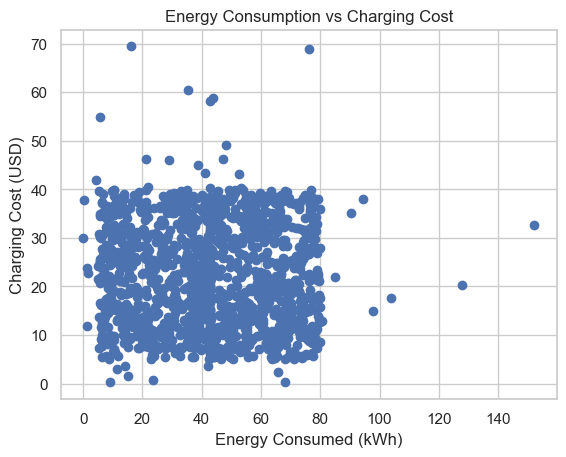

In [56]:
#Energy Vs Cost
plt.scatter(
    df["Energy Consumed (kWh)"],
    df["Charging Cost (USD)"]
)

plt.title("Energy Consumption vs Charging Cost")
plt.xlabel("Energy Consumed (kWh)")
plt.ylabel("Charging Cost (USD)")
plt.show()